In [1]:
# Week 4 - Day 2: Probability
# Probability Concepts and Distributions for Data Analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Week 4 - Day 2: Probability Analysis")
print("NumPy version:", np.__version__)

Week 4 - Day 2: Probability Analysis
NumPy version: 2.5.3


In [2]:
# Task 1: Basic Probability using a Contingency Table

data = {
    "Region": ["North", "North", "North", "North",
               "South", "South", "South", "South"],
    "Purchased": ["Yes", "Yes", "No", "No",
                  "Yes", "No", "Yes", "No"]
}

df = pd.DataFrame(data)

# Create the contingency table
contingency_table = pd.crosstab(
    df["Region"], df["Purchased"], margins=True
)

print("Contingency Table:")
display(contingency_table)

Contingency Table:


Purchased,No,Yes,All
Region,,,
North,2,2,4
South,2,2,4
All,4,4,8


In [3]:
# Define events
# A = Customer is from North
# B = Customer purchased

total_customers = len(df)

prob_A = (df["Region"] == "North").sum() / total_customers

prob_A_and_B = (
    (df["Region"] == "North") &
    (df["Purchased"] == "Yes")
).sum() / total_customers

prob_A_given_B = (
    (df["Region"] == "North") &
    (df["Purchased"] == "Yes")
).sum() / (df["Purchased"] == "Yes").sum()

print(f"P(A) = {prob_A:.2f}")
print(f"P(A ∩ B) = {prob_A_and_B:.2f}")
print(f"P(A | B) = {prob_A_given_B:.2f}")

P(A) = 0.50
P(A ∩ B) = 0.25
P(A | B) = 0.50


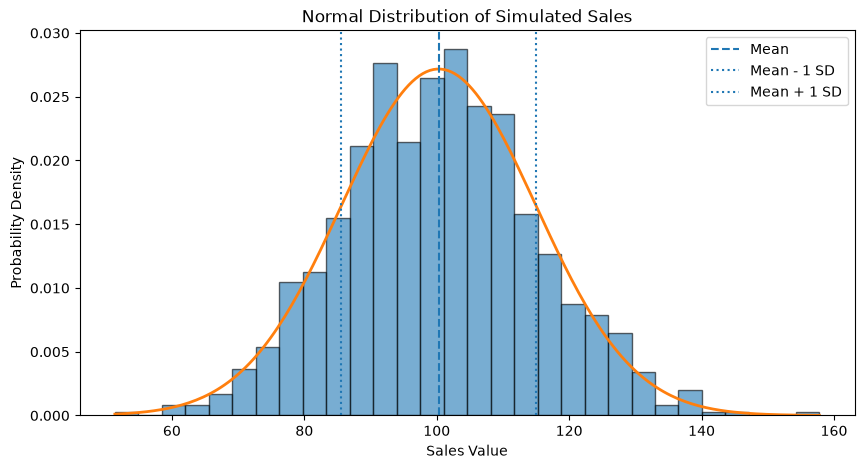

Mean: 100.29
Standard Deviation: 14.68


In [4]:
# Task 2: Normal Distribution and the 68-95-99.7 Rule

# Simulate sales data with a normal distribution
np.random.seed(42)
sales = np.random.normal(loc=100, scale=15, size=1000)

mean_sales = np.mean(sales)
std_sales = np.std(sales)

plt.figure(figsize=(10, 5))
plt.hist(sales, bins=30, density=True, alpha=0.6, edgecolor="black")

# Plot the normal distribution curve
x = np.linspace(sales.min(), sales.max(), 200)
pdf = (1 / (std_sales * np.sqrt(2 * np.pi))) * np.exp(
    -0.5 * ((x - mean_sales) / std_sales) ** 2
)
plt.plot(x, pdf, linewidth=2)

plt.axvline(mean_sales, linestyle="--", label="Mean")
plt.axvline(mean_sales - std_sales, linestyle=":", label="Mean - 1 SD")
plt.axvline(mean_sales + std_sales, linestyle=":", label="Mean + 1 SD")

plt.title("Normal Distribution of Simulated Sales")
plt.xlabel("Sales Value")
plt.ylabel("Probability Density")
plt.legend()
plt.show()

print(f"Mean: {mean_sales:.2f}")
print(f"Standard Deviation: {std_sales:.2f}")

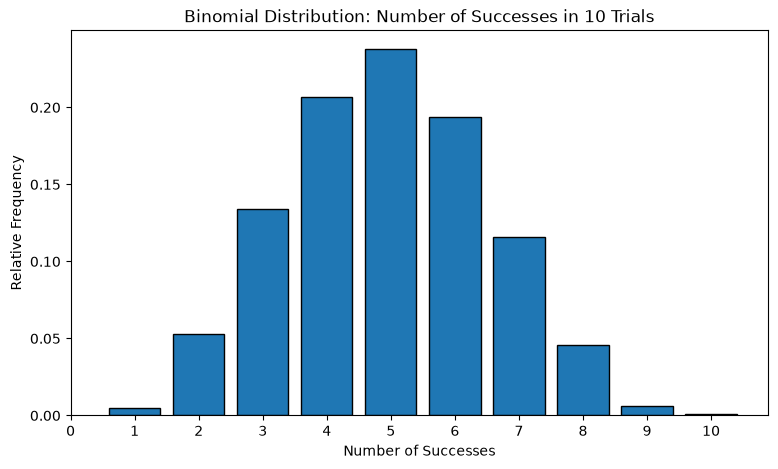

Number of simulations: 1000
Expected number of successes: 5.0
Observed average number of successes: 4.94


In [5]:
# Task 3: Simulate a Binomial Distribution using NumPy

np.random.seed(42)

# Simulate 10 trials per experiment, with probability of success = 0.5
n = 10
p = 0.5
num_simulations = 1000

binomial_results = np.random.binomial(
    n=n,
    p=p,
    size=num_simulations
)

# Plot the frequency of each number of successes
values, counts = np.unique(binomial_results, return_counts=True)

plt.figure(figsize=(9, 5))
plt.bar(values, counts / num_simulations, edgecolor="black")
plt.title("Binomial Distribution: Number of Successes in 10 Trials")
plt.xlabel("Number of Successes")
plt.ylabel("Relative Frequency")
plt.xticks(range(n + 1))
plt.show()

print("Number of simulations:", num_simulations)
print("Expected number of successes:", n * p)
print("Observed average number of successes:", round(binomial_results.mean(), 2))

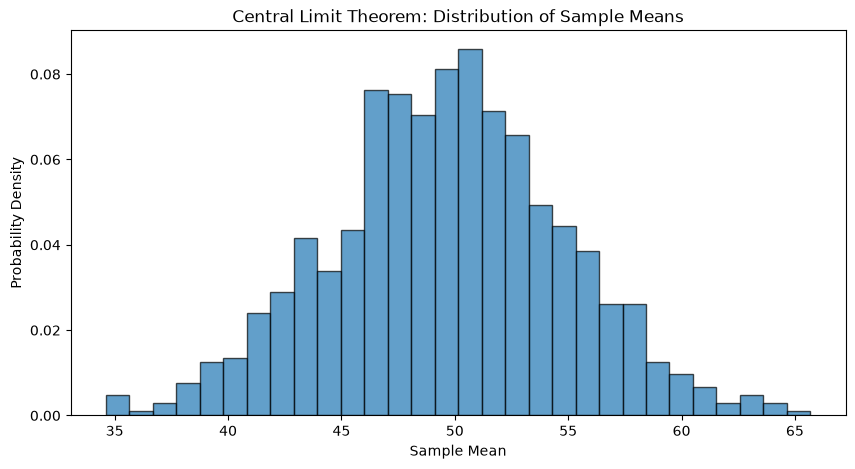

Population mean: 49.42
Mean of sample means: 49.65
Standard deviation of sample means: 5.15


In [6]:
# Task 4: Demonstrating the Central Limit Theorem (CLT)

np.random.seed(42)

# Population with a uniform distribution
population = np.random.uniform(0, 100, 10000)

# Draw many samples and calculate their means
sample_size = 30
num_samples = 1000

sample_means = [
    np.mean(np.random.choice(population, size=sample_size))
    for _ in range(num_samples)
]

# Plot the distribution of sample means
plt.figure(figsize=(10, 5))
plt.hist(sample_means, bins=30, density=True, edgecolor="black", alpha=0.7)
plt.title("Central Limit Theorem: Distribution of Sample Means")
plt.xlabel("Sample Mean")
plt.ylabel("Probability Density")
plt.show()

print(f"Population mean: {population.mean():.2f}")
print(f"Mean of sample means: {np.mean(sample_means):.2f}")
print(f"Standard deviation of sample means: {np.std(sample_means):.2f}")

In [7]:
# Final Summary and Business Interpretation

print("WEEK 4 - DAY 2: PROBABILITY ANALYSIS SUMMARY")
print("-" * 50)

print("1. Basic Probability:")
print(f"   P(North) = {prob_A:.2f}")
print(f"   P(North and Purchased) = {prob_A_and_B:.2f}")
print(f"   P(North | Purchased) = {prob_A_given_B:.2f}")

print("\n2. Normal Distribution:")
print("   The 68-95-99.7 rule describes how values cluster")
print("   around the mean in a normal distribution.")

print("\n3. Binomial Distribution:")
print(f"   Expected successes: {n * p:.2f}")
print(f"   Observed average: {binomial_results.mean():.2f}")

print("\n4. Central Limit Theorem:")
print(f"   Population mean: {population.mean():.2f}")
print(f"   Mean of sample means: {np.mean(sample_means):.2f}")
print("   Sample means form an approximately normal distribution.")

print("\nConclusion:")
print("Probability distributions help analysts quantify uncertainty,")
print("understand outcomes, and support data-driven business decisions.")

WEEK 4 - DAY 2: PROBABILITY ANALYSIS SUMMARY
--------------------------------------------------
1. Basic Probability:
   P(North) = 0.50
   P(North and Purchased) = 0.25
   P(North | Purchased) = 0.50

2. Normal Distribution:
   The 68-95-99.7 rule describes how values cluster
   around the mean in a normal distribution.

3. Binomial Distribution:
   Expected successes: 5.00
   Observed average: 4.94

4. Central Limit Theorem:
   Population mean: 49.42
   Mean of sample means: 49.65
   Sample means form an approximately normal distribution.

Conclusion:
Probability distributions help analysts quantify uncertainty,
understand outcomes, and support data-driven business decisions.
